# Feature Engineering

**Dynamic Pricing Intelligence Platform**

1. Pace features must be **relative** to what is normal for that hotel at that lead time.
2. We need **two feature sets** — one for prediction, one for causal estimation.
3. Competitor rate joins at hotel level and cannot be compared to suite rates directly.

This notebook builds the modelling table under two hard constraints:

> **No leakage.** Every feature must be computable from information available on the
> `booking_date`. Nothing may peek at the future.
>
> **Two feature sets.** Some features are excellent predictors *and* invalid causal
> controls. Section 6 proves this with numbers rather than asserting it.

## 0. Setup

In [1]:
import sys
from pathlib import Path


def find_project_root(marker: str = "requirements.txt") -> Path:
    path = Path.cwd().resolve()
    for candidate in [path, *path.parents]:
        if (candidate / marker).exists():
            return candidate
    raise RuntimeError(f"Could not find {marker} above {Path.cwd()}")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

import features as F
from db import get_engine

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

TODAY = F.TODAY
engine = get_engine()
print("Ready. TODAY =", TODAY.date())

Ready. TODAY = 2026-07-30


## 1. Load and split

### Why the split comes first

The train/validation/test split must be decided **before** any feature is built,
because several features are *fitted* (typical pace curves, for example). If those
baselines are fitted on all the data, information from the test period flows
backwards into the training features and validation scores become fiction.

### Why time-based, never random

A random split lets the model train on August and predict July. Real deployment
never works that way — you always predict forward. Random splitting on time series
inflates every metric and the model collapses in production.

| Split | Stay dates | Purpose |
|---|---|---|
| `train` | up to 2026-01-31 | fit models and baselines |
| `val` | Feb–Apr 2026 | tune hyperparameters |
| `test` | May–Jul 2026 | final honest evaluation |
| `live` | after 2026-07-30 | the unsold nights we must price |

In [2]:
raw = F.load_base(engine)
events = F.load_events(engine)
raw = F.add_split(raw)

print(f"{len(raw):,} rows loaded\n")
print(raw.groupby("split")
      .agg(rows=("rooms_booked", "size"),
           stay_dates=("stay_date", "nunique"),
           first=("stay_date", "min"),
           last=("stay_date", "max"))
      .reindex(["train", "val", "test", "live"]).to_string())

682,650 rows loaded

         rows  stay_dates      first       last
split                                          
train  494100         549 2024-08-01 2026-01-31
val     80100          89 2026-02-01 2026-04-30
test    81900          91 2026-05-01 2026-07-30
live    26550          59 2026-07-31 2026-09-27


## 2. Calendar features — the safe ones

Everything derived from the stay date is known months in advance, so none of it can
leak. This is the easy category.

**Cyclical encoding.** December 31 (day 365) and January 1 (day 1) are one day
apart, but as raw integers they are 364 apart. Sine/cosine pairs make that adjacency
explicit:

```
doy_sin = sin(2π · day_of_year / 365.25)
doy_cos = cos(2π · day_of_year / 365.25)
```

Both are needed — one alone is ambiguous, since `sin` takes the same value at two
points in the year. Tree models can learn the split points without this, but it does
not hurt them, and linear models genuinely need it.

**Events** need an interval join, not a merge: they are city-scoped and span a date
range, so each event expands to one row per day it covers.

In [3]:
df = F.add_calendar(raw, events)

cols = ["stay_date", "stay_dow", "stay_month", "doy_sin", "doy_cos",
        "stay_is_holiday", "stay_days_until_holiday", "has_event", "event_lift"]
df[cols].drop_duplicates("stay_date").head(8)

,stay_date,stay_dow,stay_month,doy_sin,doy_cos,stay_is_holiday,stay_days_until_holiday,has_event,event_lift
0,2024-08-01,3,8,-0.513901,-0.857849,False,32,False,1.0
180,2024-08-02,4,8,-0.528581,-0.848883,False,31,False,1.0
360,2024-08-03,5,8,-0.543105,-0.839665,False,30,False,1.0
540,2024-08-04,6,8,-0.557468,-0.830198,False,29,False,1.0
720,2024-08-05,0,8,-0.571667,-0.820486,False,28,False,1.0
900,2024-08-06,1,8,-0.585696,-0.810531,False,27,False,1.0
1080,2024-08-07,2,8,-0.599551,-0.800336,False,26,False,1.0
1260,2024-08-08,3,8,-0.613230,-0.789905,False,25,False,1.0


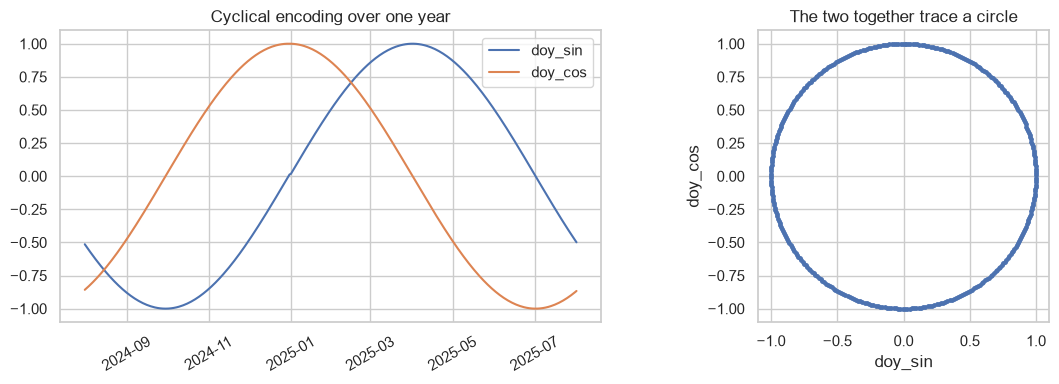

Stay dates with an event: 4.6%


In [4]:
# Sanity check the cyclical encoding: it should trace a circle over the year.
year = df.drop_duplicates("stay_date").sort_values("stay_date").head(366)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(year["stay_date"], year["doy_sin"], label="doy_sin")
axes[0].plot(year["stay_date"], year["doy_cos"], label="doy_cos")
axes[0].set_title("Cyclical encoding over one year")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend()

axes[1].scatter(year["doy_sin"], year["doy_cos"], s=6)
axes[1].set_title("The two together trace a circle")
axes[1].set_xlabel("doy_sin")
axes[1].set_ylabel("doy_cos")
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()

print(f"Stay dates with an event: {df.drop_duplicates('stay_date')['has_event'].mean():.1%}")

## 3. Price features

The rate is the **treatment** — the thing we control and whose effect we want to
measure. Three decisions here matter.

**Ratios, not dollars.** A $50 move means something completely different on a $160
room than on a $500 suite. `rate_vs_base` normalises by that room type's own
reference rate.

**Logs.** In `log(bookings) ~ log(rate)`, the coefficient *is* the elasticity: the
percentage change in bookings per percentage change in price. That is exactly the
quantity Phase 6 needs to optimise revenue.

**The competitor comparison needed fixing.** Phase 3 flagged that competitor rates
are quoted at hotel level — effectively a standard-room benchmark. Comparing a $500
suite to a $245 competitor rate produces a meaningless +104% "premium". So we scale
our rate back to a standard-room equivalent before comparing.

In [5]:
df = F.add_price_features(df)

# Before and after the standard-room adjustment
naive_gap = (df["rate"] / df["avg_competitor_rate"])
print("Naive rate / competitor rate, by room type:")
print(naive_gap.groupby(df["room_type_name"]).mean().round(2).to_string())
print("\nAfter scaling to a standard-room equivalent (rate_vs_comp):")
print(df.groupby("room_type_name")["rate_vs_comp"].mean().round(2).to_string())
print("\nThe naive version says suites are priced 100%+ above the market.")
print("They are not - they are a different product. The adjusted version is comparable.")

Naive rate / competitor rate, by room type:
room_type_name
Deluxe      1.41
Standard    1.05
Suite       2.14

After scaling to a standard-room equivalent (rate_vs_comp):
room_type_name
Deluxe      1.04
Standard    1.05
Suite       1.05

The naive version says suites are priced 100%+ above the market.
They are not - they are a different product. The adjusted version is comparable.


## 4. Pace features — the heart of revenue management

Phase 3 established that business hotels take 28% of bookings in the final week
while leisure hotels take 13%. So `occupancy_on_books = 0.40` means *nothing* on its
own. Forty percent full is excellent 50 days out and alarming 3 days out.

What a revenue manager actually says is **"we're eight points behind pace for that
night."** That is the feature we need to build:

```
pace_gap = occupancy_on_books − typical_occupancy_at_this_lead_time
```

### The baseline must be fitted on train only

`typical_occupancy` is *learned from data*, which makes it a model parameter, not a
constant. Computing it over the whole dataset would let test-period patterns inform
training features. We fit on `train` and apply everywhere.

In [6]:
train = df[df["split"] == "train"]
baseline = F.fit_pace_baseline(train)

print("Baselines fitted on TRAIN only:")
for name, table in baseline.items():
    print(f"  {name:<10} {len(table):>6,} rows")

df = F.apply_pace_baseline(df, baseline)

Baselines fitted on TRAIN only:
  pace          900 rows
  pickup        900 rows
  pace_dow    6,300 rows


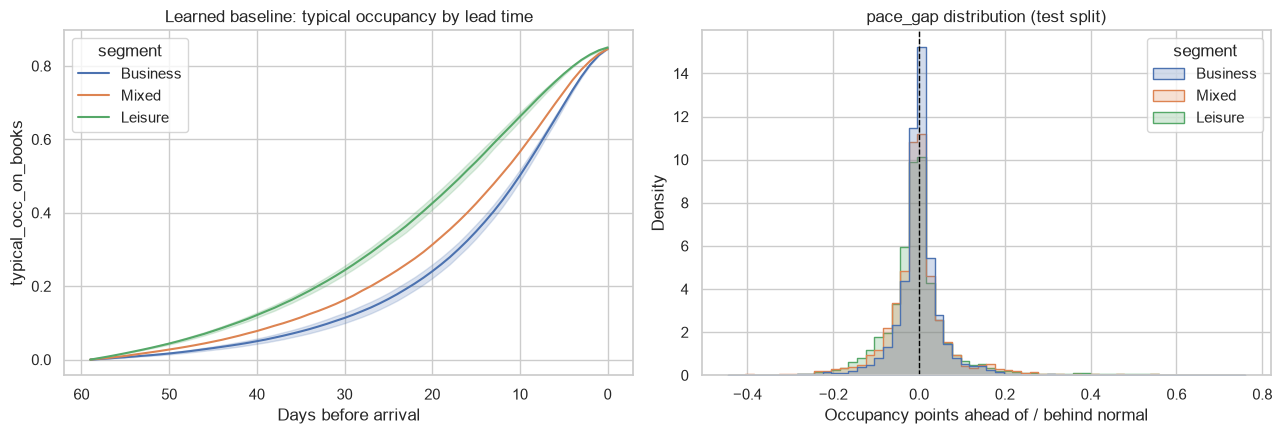

        mean    std    min    max
split                            
live   0.005  0.068 -0.354  0.680
test   0.009  0.108 -0.630  0.776
train -0.000  0.101 -0.692  0.785
val   -0.004  0.102 -0.591  0.680


In [7]:
# What the learned baseline looks like
curves = (baseline["pace"]
          .merge(df[["hotel_id", "segment"]].drop_duplicates(), on="hotel_id")
          .query("room_type_id == 'RT_STD'"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.lineplot(data=curves, x="lead_time", y="typical_occ_on_books",
             hue="segment", ax=axes[0])
axes[0].invert_xaxis()
axes[0].set_title("Learned baseline: typical occupancy by lead time")
axes[0].set_xlabel("Days before arrival")

sample = df[(df["split"] == "test") & (df["room_type_id"] == "RT_STD")]
sns.histplot(data=sample, x="pace_gap", hue="segment", bins=60,
             element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].axvline(0, color="black", ls="--", lw=1)
axes[1].set_title("pace_gap distribution (test split)")
axes[1].set_xlabel("Occupancy points ahead of / behind normal")

plt.tight_layout()
plt.show()

print(df.groupby("split")["pace_gap"].describe()[["mean", "std", "min", "max"]].round(3).to_string())

`pace_gap` is centred near zero on train by construction, and its spread on
val/test/live tells you how much genuine variation there is for a model to use.
A night sitting at +0.15 is well ahead of pace; −0.15 is well behind.

## 5. Lagged demand features — and a leak demonstration

Recent booking activity is a strong signal. Building it is also where leaks happen,
and the leak is **one missing line of code**.

To compute "average pickup over the last 3 days" you must **exclude today**. Without
`.shift(1)`, today's bookings sit inside the rolling window — and today's bookings
are the target. The feature becomes a partial copy of the answer.

We build two levels:

- `momentum_7d` — hotel-wide daily pickup, a coarse market-activity signal
- `pickup_lag_3d` — recent pickup for **this specific stay date**, much sharper

Let's build correct and leaky versions of each and compare.

In [8]:
df = F.add_momentum(df)
df = F.add_recent_pickup(df)

# --- Leaky versions, for demonstration only ---------------------------
d = df.sort_values(["hotel_id", "room_type_id", "stay_date", "booking_date"]).copy()

# Hotel-level: rolling WITHOUT the shift
daily = (d.groupby(["hotel_id", "booking_date"])["rooms_booked"]
         .sum().rename("pickup").reset_index()
         .sort_values(["hotel_id", "booking_date"]))
daily["leaky_momentum"] = (daily.groupby("hotel_id")["pickup"]
                           .rolling(7, min_periods=3).mean()
                           .reset_index(level=0, drop=True))
d = d.merge(daily[["hotel_id", "booking_date", "leaky_momentum"]],
            on=["hotel_id", "booking_date"], how="left")

# Cell-level: rolling WITHOUT the shift
d["leaky_pickup_3d"] = (d.groupby(["hotel_id", "room_type_id", "stay_date"])
                        ["rooms_booked"]
                        .transform(lambda s: s.rolling(3, min_periods=1).mean()))

comparison = pd.DataFrame([
    {"feature": "momentum_7d (hotel level)",
     "correct": d[["momentum_7d", "rooms_booked"]].dropna().corr().iloc[0, 1],
     "leaky": d[["leaky_momentum", "rooms_booked"]].dropna().corr().iloc[0, 1]},
    {"feature": "pickup_lag_3d (stay-date level)",
     "correct": d[["pickup_lag_3d", "rooms_booked"]].dropna().corr().iloc[0, 1],
     "leaky": d[["leaky_pickup_3d", "rooms_booked"]].dropna().corr().iloc[0, 1]},
])
comparison["inflation"] = comparison["leaky"] - comparison["correct"]
comparison.round(3)

,feature,correct,leaky,inflation
0,momentum_7d (hotel level),0.136,0.139,0.003
1,pickup_lag_3d (stay-date level),0.688,0.855,0.167


### The leak is invisible at hotel level and glaring at stay-date level

For `momentum_7d` the correct and leaky versions differ by almost nothing
(≈0.136 vs 0.139). That is not because the leak is harmless — it is because the
feature aggregates *every* stay date at the hotel that day, so a single cell's
bookings are a tiny fraction of the window. The leak is diluted into invisibility.

For `pickup_lag_3d` the same mistake inflates correlation from **0.69 to 0.86**.
The rolling window covers only three observations for that one night, so the target
dominates it.

**The lesson is about detection, not just prevention.** A leak in a coarsely
aggregated feature will not show up in a correlation check — you have to reason about
the construction. The rule is mechanical and worth applying without exception:

> Any rolling or expanding window on the target must be `.shift(1)` **before**
> the `.rolling()`, never after.

`pickup_lag_3d` at 0.69 is a legitimately powerful feature — the strongest in our
table. Strong correlation is not itself evidence of a leak. What matters is whether
the value would have been knowable at prediction time.

## 6. Two feature sets — the post-treatment problem

Here is the decision that separates this project from a standard ML pipeline.

Consider `occupancy_on_books`. It is one of the strongest predictors of tomorrow's
pickup. It is also **caused by the rates we already charged**. In causal language it
is a **post-treatment variable** — it sits on the path between price and bookings:

```
        rate  ──────────────────────────►  bookings
          │                                    ▲
          └──►  rooms already sold  ───────────┘
                (post-treatment)
```

Controlling for it means asking *"what is the effect of price, holding constant
something that price itself moves?"* — which subtracts part of the effect you are
trying to measure.

**The resolution is two models, not one:**

| | Demand model (Phase 5a) | Elasticity model (Phase 5b) |
|---|---|---|
| Question | How many rooms will sell? | What happens if we change price? |
| Pace features | **Use them** | **Exclude them** |
| Data | All rows | Rate tests, available rows only |
| Judged by | Forecast accuracy | Recovering the true elasticity |

Let's demonstrate the damage rather than take it on faith. Since this is synthetic
data, the true elasticity is known, so we can measure the error directly.

In [9]:
gt = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "_ground_truth_elasticity.csv")
gt = gt.set_index(["hotel_id", "room_type_id"])

# Randomized rate tests, rooms actually on sale, closed stay dates only.
sub = df[(df["split"] != "live") & df["is_rate_test"] & df["is_available"]].copy()


def elasticity_spec(cols, label):
    """Fit one Poisson model per hotel/room type and compare to ground truth."""
    rows = []
    for (h, rt), g in sub.groupby(["hotel_id", "room_type_id"]):
        X = sm.add_constant(g[cols].astype(float))
        model = sm.GLM(g["rooms_booked"], X, family=sm.families.Poisson()).fit()
        rows.append({"est": model.params["log_rate"],
                     "true": gt.loc[(h, rt), "true_elasticity"]})
    res = pd.DataFrame(rows)
    return {"specification": label,
            "mean_estimate": round(res["est"].mean(), 3),
            "MAE_vs_truth": round((res["est"] - res["true"]).abs().mean(), 3)}


specs = [
    (["log_rate", "lead_time"], "A. price + lead time"),
    (["log_rate", "lead_time", "log_comp_rate"], "B. + competitor rate (valid)"),
    (["log_rate", "lead_time", "log_comp_rate", "occupancy_on_books"],
     "C. + occupancy_on_books (POST-TREATMENT)"),
    (["log_rate", "lead_time", "log_comp_rate", "pace_gap"],
     "D. + pace_gap (POST-TREATMENT)"),
    (["log_rate", "lead_time", "log_comp_rate",
      "rooms_on_books", "pace_ratio", "pct_remaining"],
     "E. + all pace features (POST-TREATMENT)"),
]

results = pd.DataFrame([elasticity_spec(cols, label) for cols, label in specs])
results.loc[len(results)] = {"specification": "TRUE VALUE",
                             "mean_estimate": round(gt["true_elasticity"].mean(), 3),
                             "MAE_vs_truth": 0.0}
results

,specification,mean_estimate,MAE_vs_truth
0,A. price + lead time,-1.331,0.244
1,B. + competitor rate (valid),-1.503,0.130
2,C. + occupancy_on_books (POST-TREATMENT),-1.462,0.155
3,D. + pace_gap (POST-TREATMENT),-1.095,0.414
4,E. + all pace features (POST-TREATMENT),-1.302,0.251
5,TRUE VALUE,-1.471,0.000


### Read that table carefully

Specification **B** — price, lead time, and competitor rate — recovers the true
elasticity with an error of about **0.13**. That is our causal specification.

Adding pace features makes it **worse in every case**. Specification **D**, adding
`pace_gap` alone, roughly **triples** the error.

And note *why* D is the worst offender. `pace_gap` is `occupancy_on_books` with the
normal lead-time pattern subtracted out. Stripping away that exogenous variation
leaves a signal that is almost purely the *price-induced* deviation from normal — so
it is the purest mediator of the lot, and it steals the most from the estimate.

This is genuinely counterintuitive: **the better a feature is at capturing what price
did, the more damage it does to measuring what price does.** More features is not
better. It depends entirely on the question.

In [10]:
print(f"Exogenous (safe for both) : {len(F.FEATURES_EXOGENOUS):>2} features")
print(f"Price (the treatment)     : {len(F.FEATURES_PRICE):>2} features")
print(f"Post-treatment            : {len(F.FEATURES_POST_TREATMENT):>2} features")
print()
print(f"FEATURES_PREDICTIVE       : {len(F.FEATURES_PREDICTIVE):>2}  (demand model)")
print(f"FEATURES_CAUSAL           : {len(F.FEATURES_CAUSAL):>2}  (elasticity model)")
print()
print("Post-treatment features excluded from the causal set:")
for f in F.FEATURES_POST_TREATMENT:
    print(f"  - {f}")

Exogenous (safe for both) : 17 features
Price (the treatment)     :  4 features
Post-treatment            : 15 features

FEATURES_PREDICTIVE       : 36  (demand model)
FEATURES_CAUSAL           : 21  (elasticity model)

Post-treatment features excluded from the causal set:
  - rooms_on_books
  - occupancy_on_books
  - pace_gap
  - pace_gap_dow
  - pace_ratio
  - rooms_remaining
  - pct_remaining
  - typical_occ_on_books
  - typical_pickup
  - momentum_7d
  - momentum_28d
  - momentum_ratio
  - pickup_lag_1d
  - pickup_lag_3d
  - pickup_lag_7d


## 7. Leakage audit

Before saving anything, assert the constraints that make the whole table valid.
These are cheap to run and catch the errors that are otherwise invisible until a
model scores suspiciously well.

In [11]:
checks = F.leakage_checks(df)
for r in checks.itertuples():
    print(f"{'OK ' if r._2 else '!! '}{r.check:<40} {r.detail}")

assert checks["pass"].all(), "Leakage check failed - do not proceed"
print("\nAll checks passed.")

OK booking_date never after stay_date       
OK no booking_date beyond TODAY             
OK lead_time matches date difference        
OK momentum not a copy of target            corr=+0.136
OK pickup lag shifted correctly             corr=+0.688
OK pace baseline coverage                   missing=0.000%
OK no infinities                            

All checks passed.


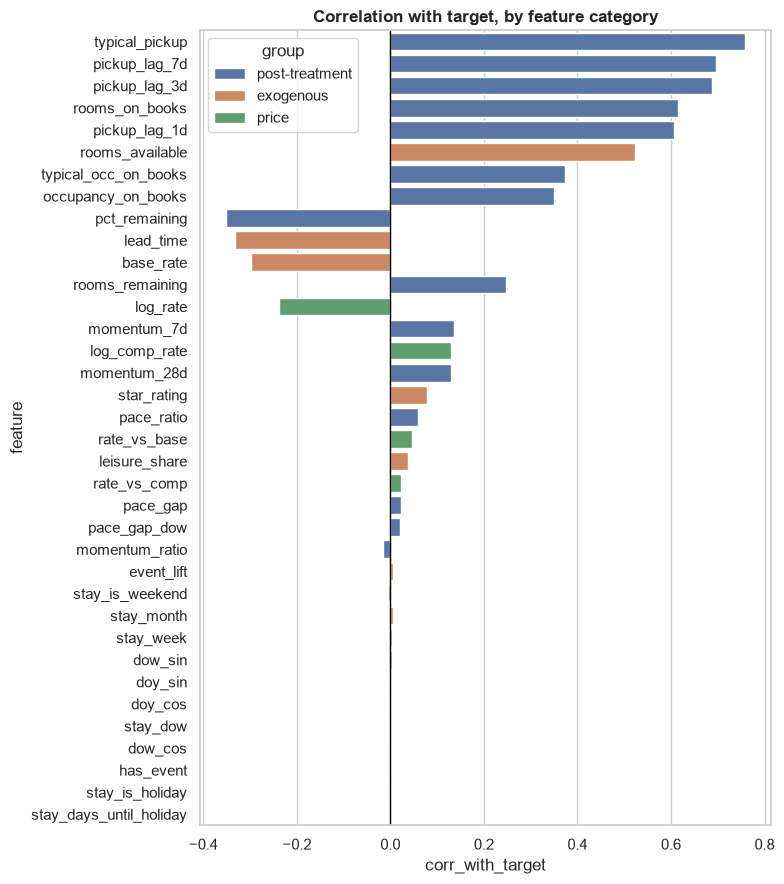

,feature,group,corr_with_target
29,typical_pickup,post-treatment,0.758
35,pickup_lag_7d,post-treatment,0.697
34,pickup_lag_3d,post-treatment,0.689
21,rooms_on_books,post-treatment,0.615
33,pickup_lag_1d,post-treatment,0.606
15,rooms_available,exogenous,0.522
28,typical_occ_on_books,post-treatment,0.372
22,occupancy_on_books,post-treatment,0.351
27,pct_remaining,post-treatment,-0.351
0,lead_time,exogenous,-0.332


In [12]:
# Feature correlations with the target, split by category.
# High correlation is not proof of a leak, but an exogenous feature that
# correlates as strongly as a post-treatment one deserves a second look.
closed = df[df["split"] != "live"]
corrs = []
for group, feats in [("exogenous", F.FEATURES_EXOGENOUS),
                     ("price", F.FEATURES_PRICE),
                     ("post-treatment", F.FEATURES_POST_TREATMENT)]:
    for f in feats:
        s = pd.to_numeric(closed[f], errors="coerce")
        corrs.append({"feature": f, "group": group,
                      "corr_with_target": s.corr(closed["rooms_booked"])})

corr_df = pd.DataFrame(corrs).sort_values("corr_with_target",
                                          key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8, 9))
sns.barplot(data=corr_df, y="feature", x="corr_with_target",
            hue="group", dodge=False, ax=ax)
ax.axvline(0, color="black", lw=1)
ax.set_title("Correlation with target, by feature category", fontweight="bold")
plt.tight_layout()
plt.show()

corr_df.head(12).round(3)

## 8. Export

Save the full table. Both Phase 5 models read from this one file, selecting
different columns — that is the point of keeping the feature sets as named lists
in `features.py` rather than hardcoding column lists in notebooks.

In [13]:
PROCESSED = PROJECT_ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

out = PROCESSED / "features.parquet"
df.to_parquet(out, index=False)

print(f"Wrote {len(df):,} rows x {df.shape[1]} columns")
print(f"  -> {out.relative_to(PROJECT_ROOT)}")
print(f"  {out.stat().st_size / 1e6:.1f} MB")
print()
print(df.groupby("split").size().reindex(["train", "val", "test", "live"]).to_string())

Wrote 682,650 rows x 55 columns
  -> data\processed\features.parquet
  26.4 MB

split
train    494100
val       80100
test      81900
live      26550


In [14]:
# Also export the post-treatment demonstration - it belongs in the README.
REPORTS = PROJECT_ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
results.to_csv(REPORTS / "post_treatment_demonstration.csv", index=False)
print("Exported reports/post_treatment_demonstration.csv")

Exported reports/post_treatment_demonstration.csv


## What Phase 5 does with this

**5a — Demand model.** Predict `rooms_booked` using `FEATURES_PREDICTIVE`. Compare
Poisson regression, Random Forest, XGBoost and CatBoost. Judged on MAE/RMSE against
the `test` split. This is the forecasting problem, and pace features earn their keep.

**5b — Elasticity model.** Estimate the causal price effect using `FEATURES_CAUSAL`,
restricted to `is_rate_test & is_available`. Judged against
`_ground_truth_elasticity.csv`, which we have not looked at except to build the table
in Section 6.

Two models, two purposes, two sets of columns. Phase 6 needs **both**: the demand
model to forecast the baseline, and the elasticity to work out how that baseline
responds when we change the price.